# EDA de viabilidad — Hito 2

Alcance: reuniones **en inglés**; etapas de **transcribir**, **separar hablantes** y **generar la minuta** (esta última, solo con AMI).
Corre sobre `hito-2/muestra/`, sin red:

```
.venv/bin/jupyter nbconvert --to notebook --execute --inplace hito-2/notebooks/eda_viabilidad.ipynb
```

Cada celda de resultado empieza con su identificador (`[V1]`, `[K3]`, `[L2]`…).
Los niveles se leen de [`niveles-a-priori.md`](../niveles-a-priori.md).

In [1]:
# [SETUP] Rutas, niveles y registro de resultados
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def raiz_hito() -> Path:
    aqui = Path.cwd().resolve()
    for c in [aqui, *aqui.parents]:
        for cand in (c, c / "hito-2"):
            if (cand / "muestra" / "MANIFIESTO.json").exists():
                return cand
    raise FileNotFoundError("No encuentro hito-2/muestra/. Corré scripts/armar_muestra.py")

HITO = raiz_hito()
M = HITO / "muestra"
FIG = HITO / "figuras"
FIG.mkdir(exist_ok=True)

def leer_niveles(ruta: Path) -> pd.DataFrame:
    filas = [[c.strip() for c in l.strip().strip("|").split("|")]
             for l in ruta.read_text(encoding="utf8").splitlines() if l.startswith("| ")]
    return pd.DataFrame(filas[1:], columns=filas[0]).set_index("Id")

NIVELES = leer_niveles(HITO / "niveles-a-priori.md")
RESULTADOS, FUGAS = [], []

def registrar(id_, resultado, cumple, tipo="medido", nota=""):
    """Anota una propiedad. cumple: 'sí', 'no', 'parcial' o 'sin decidir'."""
    fila = {"id": id_, "propiedad": NIVELES.loc[id_, "Propiedad"], "nivel": NIVELES.loc[id_, "Nivel"],
            "tipo": tipo, "resultado": resultado, "cumple": cumple, "nota": nota}
    RESULTADOS.append(fila)
    print(f"[{id_}] {fila['propiedad']}\n   nivel:     {fila['nivel']}\n   resultado: {resultado}  ({tipo})"
          f"\n   cumple:    {cumple}" + (f"\n   nota:      {nota}" if nota else ""))

def registrar_fuga(id_, busqueda, resultado):
    FUGAS.append({"id": id_, "busqueda": busqueda, "resultado": resultado})
    print(f"[{id_}] {busqueda}\n   {resultado}")

def pct(x) -> str:
    return f"{100 * x:.1f}%"

print("muestra:", M.relative_to(HITO.parent), "| generada:", json.loads((M / "MANIFIESTO.json").read_text())["generado"])
NIVELES

muestra: hito-2/muestra | generada: 2026-10-11


,Propiedad,Nivel,De dónde sale
Id,,,
V1,Volumen · transcripción en inglés,≥ 3 h y ≥ 30 hablantes distintos,Para medir la tasa de error por palabra con ±1 punto y que no dependa de pocas voces
V2,Volumen · transcripción de habla espontánea,≥ 1 h (~9.000 palabras),"El producto transcribe reuniones, no lectura"
V3,Volumen · separación de hablantes,≥ 20 sesiones y ≥ 3 h con turnos con tiempos,El error de diarización varía mucho entre sesiones; hacen falta varias para promediar
V5,Volumen · las dos etapas juntas (audio → transcripción con hablantes),"≥ 10 reuniones de ≥ 20 min con audio disponible, transcripción y hablantes con tiempos",Para medir el error que combina palabra y hablante sobre reuniones enteras
C1,Completitud · transcripción,Presente en ≥ 99% de los audios,Sin referencia no se puede medir el error
C2,Completitud · hablante,Presente en ≥ 95% de los turnos,La transcripción atribuye cada frase a una persona
C5,Completitud · datos demográficos,"Género, edad y acento en ≥ 70% de los hablantes de al menos una fuente",Para medir calidad de servicio por grupo (canvas §7)
K1,Corrección · duplicados exactos,≤ 1%,Inflan el volumen y contaminan la partición
K2,Corrección · tiempos,0 turnos con fin ≤ inicio o tiempos negativos,Invalidan la métrica de diarización


In [2]:
# [CARGA] Tablas de la muestra
ami_r = pd.read_csv(M / "ami/reuniones.csv")
ami_p = pd.read_csv(M / "ami/participantes.csv")
ami_t = pd.read_parquet(M / "ami/turnos.parquet")
ami_x = pd.read_csv(M / "ami/extractos.csv")
ami_m = pd.read_parquet(M / "ami/minutas.parquet")
icsi_r = pd.read_csv(M / "icsi/reuniones.csv")
icsi_h = pd.read_csv(M / "icsi/hablantes.csv")
icsi_t = pd.read_parquet(M / "icsi/turnos.parquet")
icsi_x = pd.read_csv(M / "icsi/extractos.csv")
vox = pd.read_parquet(M / "voxconverse/rttm.parquet")
vox_a = pd.read_csv(M / "voxconverse/audio.csv")

TABLAS = {"ami/reuniones": ami_r, "ami/participantes": ami_p, "ami/turnos": ami_t, "ami/extractos": ami_x,
          "ami/minutas": ami_m,
          "icsi/reuniones": icsi_r, "icsi/hablantes": icsi_h, "icsi/turnos": icsi_t, "icsi/extractos": icsi_x,
          "voxconverse/rttm": vox, "voxconverse/audio": vox_a}

# La duración de cada reunión es la de su audio. En AMI se guarda aparte la que declaran los metadatos (ver K3).
ami_r["duracion_declarada_s"] = ami_r.duracion_s
ami_r["duracion_s"] = ami_r.audio_duracion_s
icsi_r["ultimo_turno_s"] = icsi_r.duracion_s
icsi_r["duracion_s"] = icsi_r.audio_duracion_s

# Tablas derivadas que usan varias celdas
for t in (ami_t, icsi_t):
    t["dur"] = (t.fin - t.inicio).clip(lower=0)
icsi_h["genero"] = icsi_h.genero.str.lower()          # viene escrito de cuatro formas (ver K4)
ami_habla = ami_t[ami_t.n_palabras > 0].merge(ami_p, on="hablante", how="left")
icsi_habla = icsi_t[icsi_t.n_palabras > 0].merge(icsi_h, on="hablante", how="left")
vox_s = (vox.assign(fin=vox.inicio + vox.duracion).groupby(["particion", "sesion"])
         .agg(duracion_s=("fin", "max"), n_hablantes=("hablante", "nunique")).reset_index())
H = lambda segundos: segundos / 3600

pd.DataFrame([{"tabla": k, "filas": len(v), "columnas": ", ".join(v.columns)} for k, v in TABLAS.items()])

,tabla,filas,columnas
0,ami/reuniones,171,"reunion, serie, tipo, fecha_cruda, anio, duracion_s, n_hablantes, hablantes, particion_oficial, particion_..."
1,ami/participantes,189,"hablante, sexo, edad, lengua_nativa"
2,ami/turnos,93637,"reunion, agente, hablante, inicio, fin, n_palabras, texto, dur"
3,ami/extractos,16,"reunion, archivo, inicio_s, duracion_s"
4,ami/minutas,2649,"reunion, tipo, orden, item_id, texto"
5,icsi/reuniones,75,"reunion, grupo, duracion_s, n_hablantes, hablantes, palabras, palabras_sin_tiempo, audio_disponible, audio..."
6,icsi/hablantes,61,"hablante, genero, edad, educacion, nativo_ingles, fecha_formulario"
7,icsi/turnos,129106,"reunion, agente, hablante, inicio, fin, lectura_de_digitos, n_palabras, texto, dur"
8,icsi/extractos,8,"reunion, archivo, inicio_s, duracion_s"
9,voxconverse/rttm,27747,"particion, sesion, hablante, inicio, duracion"


In [3]:
# [ESCUCHAR] Reproduce el extracto de 30 s de una reunión, por su identificador
from IPython.display import Audio, display

EXTRACTOS = pd.concat([ami_x.assign(corpus="ami"), icsi_x.assign(corpus="icsi")]).set_index("reunion")

def escuchar(reunion: str):
    """Muestra el reproductor del extracto y lo que dice la transcripción en esos 30 s."""
    if reunion not in EXTRACTOS.index:
        raise KeyError(f"'{reunion}' no tiene extracto. Opciones: {', '.join(EXTRACTOS.index)}")
    x = EXTRACTOS.loc[reunion]
    datos, hz = sf.read(M / x.corpus / x.archivo, dtype="float32", always_2d=True)
    turnos = ami_t if x.corpus == "ami" else icsi_t
    t = turnos[(turnos.reunion == reunion) & (turnos.fin > x.inicio_s) & (turnos.inicio < x.inicio_s + x.duracion_s)]
    print(f"{reunion} ({x.corpus.upper()}) · segundos {x.inicio_s}–{x.inicio_s + x.duracion_s} de la reunión")
    display(Audio(datos.mean(axis=1), rate=hz))
    return t[["hablante", "inicio", "fin", "texto"]].sort_values("inicio").reset_index(drop=True)

# Identificadores con extracto (descomentá uno para probarlo):
# AMI:  ES2005c ES2007c ES2012c ES2014d IS1002d IS1003a IS1004b IS1006a
#       TS3005c TS3008a TS3010a TS3012c EN2001b EN2009d IB4003 IB4004
# ICSI: Bmr006 Bmr026 Bmr030 Bro010 Bro018 Bro025 Bed006 Bed015
# escuchar("ES2005c")
# escuchar("EN2001b")
# escuchar("Bmr006")
escuchar("TS3008a")

TS3008a (AMI) · segundos 416–446 de la reunión


,hablante,inicio,fin,texto
0,MTD029PM,414.176,418.176,It's doing some stuff now. So you can use a pen. You can use an eraser.
1,MTD031UID,415.471,416.386,Little bit slower.
2,MTD029PM,420.960,434.016,"And you can make new uh fi uh new blanks, and you can change uh the line width and the colour of the pen b..."
3,MTD029PM,435.772,438.160,And then select current colour or line width.
4,MTD029PM,439.856,440.976,"So, it's quite easy."
5,MTD029PM,442.535,447.807,"Uh well, now you're all uh acquainted with the different tools."


## 1. Volumen

In [4]:
# [V1] Volumen · transcripción en inglés
vol = pd.DataFrame([
    {"fuente": "AMI", "reuniones": len(ami_r), "horas_de_audio": H(ami_r.duracion_s.sum()),
     "palabras": int(ami_r.palabras.sum()), "hablantes": ami_t.hablante.nunique()},
    {"fuente": "ICSI", "reuniones": len(icsi_r), "horas_de_audio": H(icsi_r.duracion_s.sum()),
     "palabras": int(icsi_r.palabras.sum()), "hablantes": icsi_t.hablante.nunique()},
])
display(vol.round(1))
h_total, n_hab = vol.horas_de_audio.sum(), int(vol.hablantes.sum())
registrar("V1", f"{h_total:.1f} h de reuniones transcriptas y {n_hab} hablantes "
                f"(AMI: {vol.horas_de_audio[0]:.1f} h y {vol.hablantes[0]} hablantes; "
                f"ICSI: {vol.horas_de_audio[1]:.1f} h y {vol.hablantes[1]})",
          "sí" if h_total >= 3 and n_hab >= 30 else "no",
          nota=f"{int(vol.palabras.sum())} palabras")

,fuente,reuniones,horas_de_audio,palabras,hablantes
0,AMI,171,100.0,978214,190
1,ICSI,75,71.7,816026,60


[V1] Volumen · transcripción en inglés
   nivel:     ≥ 3 h y ≥ 30 hablantes distintos
   resultado: 171.6 h de reuniones transcriptas y 250 hablantes (AMI: 100.0 h y 190 hablantes; ICSI: 71.7 h y 60)  (medido)
   cumple:    sí
   nota:      1794240 palabras


In [5]:
# [V2] Volumen · transcripción de habla espontánea
esp_ami = ami_t[ami_t.n_palabras > 0]
esp_icsi = icsi_t[(icsi_t.n_palabras > 0) & ~icsi_t.lectura_de_digitos]
pal = int(esp_ami.n_palabras.sum() + esp_icsi.n_palabras.sum())
h_habla = H(esp_ami.dur.sum() + esp_icsi.dur.sum())
registrar("V2", f"{pal} palabras de habla espontánea en {h_habla:.1f} h de habla efectiva "
                f"(sin silencios ni lectura de dígitos)",
          "sí" if pal >= 9000 and h_habla >= 1 else "no")

[V2] Volumen · transcripción de habla espontánea
   nivel:     ≥ 1 h (~9.000 palabras)
   resultado: 1764238 palabras de habla espontánea en 164.0 h de habla efectiva (sin silencios ni lectura de dígitos)  (medido)
   cumple:    sí


In [6]:
# [V3] Volumen · separación de hablantes (sesiones con turnos con tiempos)
diar = pd.DataFrame([
    {"fuente": "AMI", "sesiones": len(ami_r), "horas": H(ami_r.duracion_s.sum()), "transcripción": "sí"},
    {"fuente": "ICSI", "sesiones": len(icsi_r), "horas": H(icsi_r.duracion_s.sum()), "transcripción": "sí"},
    {"fuente": "VoxConverse", "sesiones": len(vox_s), "horas": H(vox_s.duracion_s.sum()), "transcripción": "no"},
])
display(diar.round(1))
registrar("V3", f"{int(diar.sesiones.sum())} sesiones y {diar.horas.sum():.0f} h con turnos con tiempos "
                f"(AMI {len(ami_r)}, ICSI {len(icsi_r)}, VoxConverse {len(vox_s)})",
          "sí" if diar.sesiones.sum() >= 20 and diar.horas.sum() >= 3 else "no")

,fuente,sesiones,horas,transcripción
0,AMI,171,100.0,sí
1,ICSI,75,71.7,sí
2,VoxConverse,448,63.5,no


[V3] Volumen · separación de hablantes
   nivel:     ≥ 20 sesiones y ≥ 3 h con turnos con tiempos
   resultado: 694 sesiones y 235 h con turnos con tiempos (AMI 171, ICSI 75, VoxConverse 448)  (medido)
   cumple:    sí


In [7]:
# [V5] Volumen · las dos etapas juntas: reuniones de ≥ 20 min con audio, transcripción y hablantes con tiempos
def completas(r, t):
    con_tiempos = t[t.inicio.notna() & t.fin.notna() & t.hablante.notna()].reunion.unique()
    return r[(r.duracion_s >= 20 * 60) & r.audio_disponible & (r.palabras > 0) & r.reunion.isin(con_tiempos)]

c_ami, c_icsi = completas(ami_r, ami_t), completas(icsi_r, icsi_t)
display(pd.DataFrame([
    {"fuente": "AMI", "reuniones": len(ami_r), "de_20_min_o_mas": int((ami_r.duracion_s >= 1200).sum()),
     "con_audio_disponible": int(ami_r.audio_disponible.sum()), "cumplen_todo": len(c_ami)},
    {"fuente": "ICSI", "reuniones": len(icsi_r), "de_20_min_o_mas": int((icsi_r.duracion_s >= 1200).sum()),
     "con_audio_disponible": int(icsi_r.audio_disponible.sum()), "cumplen_todo": len(c_icsi)},
]))
n = len(c_ami) + len(c_icsi)
registrar("V5", f"{n} reuniones de 20 minutos o más con audio disponible, transcripción y hablantes con tiempos "
                f"({len(c_ami)} de AMI y {len(c_icsi)} de ICSI; {H(c_ami.duracion_s.sum() + c_icsi.duracion_s.sum()):.0f} h)",
          "sí" if n >= 10 else "no")

,fuente,reuniones,de_20_min_o_mas,con_audio_disponible,cumplen_todo
0,AMI,171,148,171,148
1,ICSI,75,74,75,74


[V5] Volumen · las dos etapas juntas (audio → transcripción con hablantes)
   nivel:     ≥ 10 reuniones de ≥ 20 min con audio disponible, transcripción y hablantes con tiempos
   resultado: 222 reuniones de 20 minutos o más con audio disponible, transcripción y hablantes con tiempos (148 de AMI y 74 de ICSI; 165 h)  (medido)
   cumple:    sí


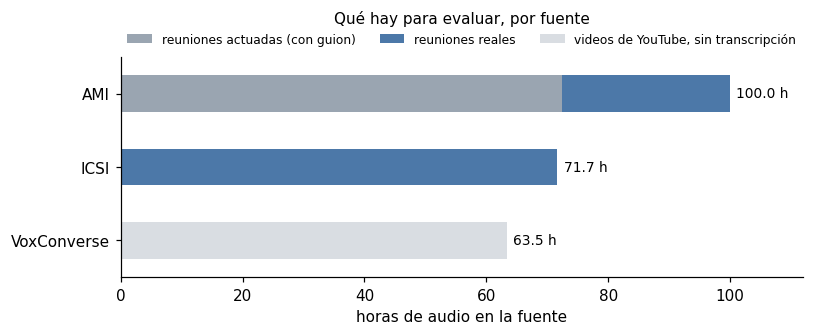

In [8]:
# [FIG1] Horas por fuente y tipo de reunión
partes = pd.DataFrame({
    "reuniones actuadas (con guion)": [H(ami_r[ami_r.tipo == "scenario"].duracion_s.sum()), 0, 0],
    "reuniones reales": [H(ami_r[ami_r.tipo == "nonscenario"].duracion_s.sum()), H(icsi_r.duracion_s.sum()), 0],
    "videos de YouTube, sin transcripción": [0, 0, H(vox_s.duracion_s.sum())],
}, index=["AMI", "ICSI", "VoxConverse"]).iloc[::-1]
ax = partes.plot.barh(stacked=True, figsize=(8, 2.6), color=["#9aa5b1", "#4c78a8", "#d9dde2"])
for y, v in enumerate(partes.sum(axis=1)):
    ax.text(v + 1, y, f"{v:.1f} h", va="center", fontsize=9)
ax.set_xlabel("horas de audio en la fuente"); ax.set_xlim(0, partes.sum(axis=1).max() * 1.12)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(.5, 1.0))
ax.set_title("Qué hay para evaluar, por fuente", fontsize=10, pad=22)
plt.savefig(FIG / "fig1_horas_por_fuente.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Completitud

In [9]:
# [C1] Completitud · transcripción presente en los audios
c1 = pd.DataFrame([
    {"fuente": "AMI", "audios_disponibles": int(ami_r.audio_disponible.sum()),
     "con_transcripcion": int((ami_r.audio_disponible & (ami_r.palabras > 0)).sum()),
     "reuniones_sin_audio": ", ".join(ami_r[~ami_r.audio_disponible].reunion) or "ninguna",
     "palabras_sin_tiempo": ami_r.palabras_sin_tiempo.sum() / ami_r.palabras.sum()},
    {"fuente": "ICSI", "audios_disponibles": int(icsi_r.audio_disponible.sum()),
     "con_transcripcion": int((icsi_r.audio_disponible & (icsi_r.palabras > 0)).sum()),
     "reuniones_sin_audio": ", ".join(icsi_r[~icsi_r.audio_disponible].reunion) or "ninguna",
     "palabras_sin_tiempo": icsi_r.palabras_sin_tiempo.sum() / icsi_r.palabras.sum()},
])
c1["pct"] = c1.con_transcripcion / c1.audios_disponibles
display(c1.assign(pct=c1.pct.map(pct), palabras_sin_tiempo=c1.palabras_sin_tiempo.map(pct)))
peores = ami_r.assign(p=ami_r.palabras_sin_tiempo / ami_r.palabras).nlargest(4, "p")[["reunion", "p"]]
print("AMI · reuniones con más palabras sin tiempo:", {r: pct(p) for r, p in zip(peores.reunion, peores.p)})
registrar("C1", f"AMI: {pct(c1.pct[0])} de los {c1.audios_disponibles[0]} audios disponibles tienen transcripción. "
                f"ICSI: {pct(c1.pct[1])} de {c1.audios_disponibles[1]}. Palabras sin tiempo: "
                f"{pct(c1.palabras_sin_tiempo[0])} en AMI y {pct(c1.palabras_sin_tiempo[1])} en ICSI",
          "sí" if c1.pct.min() >= .99 else "no",
          nota="VoxConverse no tiene transcripción: solo sirve para separar hablantes")

,fuente,audios_disponibles,con_transcripcion,reuniones_sin_audio,palabras_sin_tiempo,pct
0,AMI,171,171,ninguna,0.0%,100.0%
1,ICSI,75,75,ninguna,11.5%,100.0%


AMI · reuniones con más palabras sin tiempo: {'ES2008a': '0.1%', 'EN2001a': '0.0%', 'EN2001b': '0.0%', 'EN2001d': '0.0%'}
[C1] Completitud · transcripción
   nivel:     Presente en ≥ 99% de los audios
   resultado: AMI: 100.0% de los 171 audios disponibles tienen transcripción. ICSI: 100.0% de 75. Palabras sin tiempo: 0.0% en AMI y 11.5% en ICSI  (medido)
   cumple:    sí
   nota:      VoxConverse no tiene transcripción: solo sirve para separar hablantes


In [10]:
# [C2] Completitud · hablante presente en cada turno
c2 = pd.DataFrame([
    {"fuente": "AMI", "turnos": len(ami_t), "con_hablante": ami_t.hablante.notna().mean(),
     "sin_palabras": (ami_t.n_palabras == 0).mean()},
    {"fuente": "ICSI", "turnos": len(icsi_t), "con_hablante": icsi_t.hablante.notna().mean(),
     "sin_palabras": (icsi_t.n_palabras == 0).mean()},
    {"fuente": "VoxConverse", "turnos": len(vox), "con_hablante": vox.hablante.notna().mean(), "sin_palabras": np.nan},
])
display(c2.assign(con_hablante=c2.con_hablante.map(pct), sin_palabras=c2.sin_palabras.map(lambda v: pct(v) if pd.notna(v) else "—")))
registrar("C2", f"{pct(c2.con_hablante.min())} de los turnos tienen hablante en las tres fuentes",
          "sí" if c2.con_hablante.min() >= .95 else "no",
          nota=f"Turnos sin palabras (risas, ruidos): {pct(c2.sin_palabras[0])} en AMI y {pct(c2.sin_palabras[1])} en ICSI")

,fuente,turnos,con_hablante,sin_palabras
0,AMI,93637,100.0%,10.8%
1,ICSI,129106,100.0%,15.8%
2,VoxConverse,27747,100.0%,—


[C2] Completitud · hablante
   nivel:     Presente en ≥ 95% de los turnos
   resultado: 100.0% de los turnos tienen hablante en las tres fuentes  (medido)
   cumple:    sí
   nota:      Turnos sin palabras (risas, ruidos): 10.8% en AMI y 15.8% en ICSI


In [11]:
# [C5] Completitud · género, edad y acento por hablante
ami_presentes = pd.DataFrame({"hablante": ami_t.hablante.unique()}).merge(ami_p, on="hablante", how="left")
icsi_presentes = pd.DataFrame({"hablante": icsi_t.hablante.unique()}).merge(icsi_h, on="hablante", how="left")
c5 = pd.DataFrame([
    {"fuente": "AMI", "hablantes": len(ami_presentes), "género": ami_presentes.sexo.notna().mean(),
     "edad": ami_presentes.edad.notna().mean(), "acento (lengua nativa)": ami_presentes.lengua_nativa.notna().mean(),
     "los_tres": ami_presentes[["sexo", "edad", "lengua_nativa"]].notna().all(axis=1).mean()},
    {"fuente": "ICSI", "hablantes": len(icsi_presentes), "género": icsi_presentes.genero.notna().mean(),
     "edad": icsi_presentes.edad.notna().mean(), "acento (lengua nativa)": icsi_presentes.nativo_ingles.notna().mean(),
     "los_tres": icsi_presentes[["genero", "edad", "nativo_ingles"]].notna().all(axis=1).mean()},
])
display(c5.set_index("fuente").drop(columns="hablantes").map(pct).assign(hablantes=c5.hablantes.values))
registrar("C5", f"AMI: {pct(c5.los_tres[0])} de sus {c5.hablantes[0]} hablantes tienen género, edad y lengua nativa. "
                f"ICSI: {pct(c5.los_tres[1])} de {c5.hablantes[1]} (falta sobre todo la edad: {pct(c5.edad[1])})",
          "sí" if c5.los_tres.max() >= .70 else "no")

,género,edad,acento (lengua nativa),los_tres,hablantes
fuente,,,,,
AMI,78.9%,64.7%,77.9%,64.7%,190
ICSI,98.3%,75.0%,100.0%,75.0%,60


[C5] Completitud · datos demográficos
   nivel:     Género, edad y acento en ≥ 70% de los hablantes de al menos una fuente
   resultado: AMI: 64.7% de sus 190 hablantes tienen género, edad y lengua nativa. ICSI: 75.0% de 60 (falta sobre todo la edad: 75.0%)  (medido)
   cumple:    sí


## 3. Corrección

In [12]:
# [K1] Corrección · duplicados exactos
k1 = pd.DataFrame([
    ("ami/reuniones · mismo identificador", len(ami_r), ami_r.reunion.duplicated().sum()),
    ("icsi/reuniones · mismo identificador", len(icsi_r), icsi_r.reunion.duplicated().sum()),
    ("ami/turnos · misma reunión, hablante, tiempos y texto", len(ami_t), ami_t.duplicated(["reunion", "agente", "inicio", "fin", "texto"]).sum()),
    ("icsi/turnos · misma reunión, hablante, tiempos y texto", len(icsi_t), icsi_t.duplicated(["reunion", "agente", "inicio", "fin", "texto"]).sum()),
    ("voxconverse/rttm · misma fila", len(vox), vox.duplicated().sum()),
    ("ami + icsi · mismo tamaño de audio", int(ami_r.audio_disponible.sum() + icsi_r.audio_disponible.sum()),
     pd.concat([ami_r.audio_bytes, icsi_r.audio_bytes]).dropna().duplicated().sum()),
], columns=["tabla", "filas", "duplicados"])
k1["pct"] = (k1.duplicados / k1.filas).map(pct)
display(k1)
registrar("K1", f"{int(k1.duplicados.sum())} duplicados exactos en {len(k1)} comprobaciones "
                f"(máximo {pct((k1.duplicados / k1.filas).max())})",
          "sí" if (k1.duplicados / k1.filas).max() <= .01 else "no")

,tabla,filas,duplicados,pct
0,ami/reuniones · mismo identificador,171,0,0.0%
1,icsi/reuniones · mismo identificador,75,0,0.0%
2,"ami/turnos · misma reunión, hablante, tiempos y texto",93637,0,0.0%
3,"icsi/turnos · misma reunión, hablante, tiempos y texto",129106,0,0.0%
4,voxconverse/rttm · misma fila,27747,0,0.0%
5,ami + icsi · mismo tamaño de audio,246,0,0.0%


[K1] Corrección · duplicados exactos
   nivel:     ≤ 1%
   resultado: 0 duplicados exactos en 6 comprobaciones (máximo 0.0%)  (medido)
   cumple:    sí


In [13]:
# [K2] Corrección · turnos con tiempos imposibles
def malos(t, ini="inicio", fin="fin"):
    return int(((t[fin] <= t[ini]) | (t[ini] < 0)).sum())

k2 = pd.DataFrame([
    ("ami/turnos", len(ami_t), malos(ami_t), int(ami_t[["inicio", "fin"]].isna().any(axis=1).sum())),
    ("icsi/turnos", len(icsi_t), malos(icsi_t), int(icsi_t[["inicio", "fin"]].isna().any(axis=1).sum())),
    ("voxconverse/rttm", len(vox), int(((vox.duracion <= 0) | (vox.inicio < 0)).sum()), int(vox[["inicio", "duracion"]].isna().any(axis=1).sum())),
], columns=["tabla", "turnos", "fin_menor_o_igual_que_inicio", "sin_tiempo"])
display(k2)
display(ami_t[ami_t.fin <= ami_t.inicio][["reunion", "hablante", "inicio", "fin", "texto"]])
# Turnos que terminan después de que termina el audio de su reunión
pasados = ami_t.merge(ami_r[["reunion", "audio_duracion_s"]], on="reunion")
pasados_icsi = icsi_t.merge(icsi_r[["reunion", "audio_duracion_s"]], on="reunion")
n_pas = int((pasados.fin > pasados.audio_duracion_s + 1).sum()), int((pasados_icsi.fin > pasados_icsi.audio_duracion_s + 1).sum())
print("Turnos que terminan más de 1 s después del final del audio -> AMI:", n_pas[0], "| ICSI:", n_pas[1])
total = int(k2.fin_menor_o_igual_que_inicio.sum())
registrar("K2", f"{total} turnos con fin ≤ inicio (AMI {k2.fin_menor_o_igual_que_inicio[0]}, ICSI "
                f"{k2.fin_menor_o_igual_que_inicio[1]}, VoxConverse {k2.fin_menor_o_igual_que_inicio[2]}). "
                f"{n_pas[0] + n_pas[1]} turnos terminan después del final del audio",
          "sí" if total == 0 else "no",
          nota="Se descartan por regla" if total else "")

,tabla,turnos,fin_menor_o_igual_que_inicio,sin_tiempo
0,ami/turnos,93637,2,0
1,icsi/turnos,129106,0,3
2,voxconverse/rttm,27747,0,0


,reunion,hablante,inicio,fin,texto
7545,EN2005a,FEE085,91.472,90.461,Okay.
29674,ES2011c,FEE043,78.122,78.001,


Turnos que terminan más de 1 s después del final del audio -> AMI: 5 | ICSI: 1
[K2] Corrección · tiempos
   nivel:     0 turnos con fin ≤ inicio o tiempos negativos
   resultado: 2 turnos con fin ≤ inicio (AMI 2, ICSI 0, VoxConverse 0). 6 turnos terminan después del final del audio  (medido)
   cumple:    no
   nota:      Se descartan por regla


In [14]:
# [K3] Corrección · audio legible y con la duración declarada
def formato(r):
    return r[r.audio_disponible].groupby(["audio_hz", "audio_canales", "audio_bits"]).size().to_dict()

# AMI declara la duración de cada reunión en sus metadatos; se compara con la duración real del audio.
a = ami_r[ami_r.audio_disponible].assign(dif=lambda d: (d.audio_duracion_s - d.duracion_declarada_s).abs())
a["coincide"] = a.dif <= 0.01 * a.duracion_declarada_s           # tolerancia: 1% de la duración
# Segunda comprobación, para las dos fuentes: el audio dura al menos hasta el último turno anotado.
a["cubre"] = a.audio_duracion_s >= a.reunion.map(ami_t.groupby("reunion").fin.max()) - 1
i = icsi_r[icsi_r.audio_disponible].assign(coincide=lambda d: d.audio_duracion_s >= d.ultimo_turno_s - 1)

cot = []
for corpus, tabla, r in (("ami", ami_x, ami_r), ("icsi", icsi_x, icsi_r)):
    for _, x in tabla.iterrows():
        info = sf.info(M / corpus / x.archivo)
        ref = r.set_index("reunion").loc[x.reunion]
        cot.append({"corpus": corpus, "reunion": x.reunion, "segundos": info.frames / info.samplerate,
                    "hz": info.samplerate, "hz_indice": ref.audio_hz, "canales": info.channels,
                    "coincide": abs(info.frames / info.samplerate - x.duracion_s) < 1e-3 and info.samplerate == ref.audio_hz})
cot = pd.DataFrame(cot)

k3 = pd.DataFrame([
    ("AMI · audio disponible en el servidor", len(ami_r), ami_r.audio_disponible.mean()),
    ("AMI · la duración del audio coincide con la declarada en los metadatos (±1%)", len(a), a.coincide.mean()),
    ("AMI · el audio cubre hasta el último turno anotado", len(a), a.cubre.mean()),
    ("ICSI · audio disponible en el servidor", len(icsi_r), icsi_r.audio_disponible.mean()),
    ("ICSI · el audio cubre hasta el último turno anotado", len(i), i.coincide.mean()),
    ("Extractos de la muestra · se leen y coinciden con el índice", len(cot), cot.coincide.mean()),
], columns=["comprobación", "archivos", "cumplen"])
display(k3.assign(cumplen=k3.cumplen.map(pct)))
print("Formato (Hz, canales, bits) -> AMI:", formato(ami_r), "| ICSI:", formato(icsi_r))
print("Peso del audio completo -> AMI:", f"{ami_r.audio_bytes.sum() / 1e9:.1f} GB", "| ICSI:", f"{icsi_r.audio_bytes.sum() / 1e9:.1f} GB",
      "| VoxConverse:", f"{vox_a.audio_bytes.sum() / 1e9:.1f} GB", "(disponible:", bool(vox_a.audio_disponible.all()), ")")
print("AMI · mayores diferencias con los metadatos:",
      a.nlargest(3, "dif")[["reunion", "duracion_declarada_s", "audio_duracion_s"]].round(0).to_dict("records"))
legibles = min(ami_r.audio_disponible.mean(), icsi_r.audio_disponible.mean())
ok = min(a.coincide.mean(), i.coincide.mean(), cot.coincide.mean())
registrar("K3", f"Audio disponible: {int(ami_r.audio_disponible.sum())} de {len(ami_r)} en AMI y "
                f"{int(icsi_r.audio_disponible.sum())} de {len(icsi_r)} en ICSI. El audio cubre todos los turnos anotados en "
                f"{pct(a.cubre.mean())} de AMI y {pct(i.coincide.mean())} de ICSI. La duración de los metadatos de AMI "
                f"coincide con el audio solo en {pct(a.coincide.mean())}. {int(cot.coincide.sum())} de {len(cot)} extractos "
                f"se leen y coinciden con el índice",
          "sí" if legibles >= .99 and ok >= .99 else ("parcial" if cot.coincide.mean() >= .99 else "no"),
          nota="La duración declarada en los metadatos de AMI no es confiable: se usa la del audio")

,comprobación,archivos,cumplen
0,AMI · audio disponible en el servidor,171,100.0%
1,AMI · la duración del audio coincide con la declarada en los metadatos (±1%),171,80.1%
2,AMI · el audio cubre hasta el último turno anotado,171,99.4%
3,ICSI · audio disponible en el servidor,75,100.0%
4,ICSI · el audio cubre hasta el último turno anotado,75,98.7%
5,Extractos de la muestra · se leen y coinciden con el índice,24,100.0%


Formato (Hz, canales, bits) -> AMI: {(16000, 1, 16): 170, (16000, 2, 16): 1} | ICSI: {(16000, 1, 16): 75}
Peso del audio completo -> AMI: 11.5 GB | ICSI: 8.3 GB | VoxConverse: 6.3 GB (disponible: True )
AMI · mayores diferencias con los metadatos: [{'reunion': 'ES2005a', 'duracion_declarada_s': 958.0, 'audio_duracion_s': 478.0}, {'reunion': 'TS3011d', 'duracion_declarada_s': 1921.0, 'audio_duracion_s': 2157.0}, {'reunion': 'TS3008c', 'duracion_declarada_s': 2340.0, 'audio_duracion_s': 2508.0}]
[K3] Corrección · audio
   nivel:     ≥ 99% de los archivos legibles y con la duración declarada
   resultado: Audio disponible: 171 de 171 en AMI y 75 de 75 en ICSI. El audio cubre todos los turnos anotados en 99.4% de AMI y 98.7% de ICSI. La duración de los metadatos de AMI coincide con el audio solo en 80.1%. 24 de 24 extractos se leen y coinciden con el índice  (medido)
   cumple:    parcial
   nota:      La duración declarada en los metadatos de AMI no es confiable: se usa la del audio


In [15]:
# [K4] Corrección · texto con caracteres ajenos al inglés, después de normalizar por reglas
PERMITIDOS = set("abcdefghijklmnopqrstuvwxyz0123456789 .,;:?!\"'()-%&$/_")

def normalizar(t: str) -> str:
    return re.sub(r"\s+", " ", (t or "").lower()).strip()

def ajenos(serie: pd.Series) -> pd.Series:
    return serie.map(lambda t: "".join(sorted(set(normalizar(t)) - PERMITIDOS)))

k4 = []
for nombre, serie in [("AMI", ami_t.texto[ami_t.n_palabras > 0]), ("ICSI", icsi_t.texto[icsi_t.n_palabras > 0])]:
    aj = ajenos(serie)
    k4.append({"fuente": nombre, "turnos_con_palabras": len(serie), "con_ajenos": (aj != "").mean(),
               "caracteres_ajenos": "".join(sorted(set("".join(aj))))[:40]})
k4 = pd.DataFrame(k4)
display(k4.assign(con_ajenos=k4.con_ajenos.map(pct)))
print("ICSI · formas en que venía escrito el género:", pd.read_csv(M / "icsi/hablantes.csv").genero.value_counts().to_dict())
print("AMI · formatos de fecha distintos en 'fecha_cruda':", ami_r.fecha_cruda.str.replace(r"\d", "9", regex=True).value_counts().to_dict())
registrar("K4", "; ".join(f"{f}: {pct(v)}" for f, v in zip(k4.fuente, k4.con_ajenos)) + " de los turnos con caracteres ajenos",
          "sí" if k4.con_ajenos.max() <= .01 else "no")

,fuente,turnos_con_palabras,con_ajenos,caracteres_ajenos
0,AMI,83483,0.0%,*@
1,ICSI,108660,0.4%,@


ICSI · formas en que venía escrito el género: {'Male': 40, 'Female': 13, 'male': 4, 'female': 3}
AMI · formatos de fecha distintos en 'fecha_cruda': {'99-99-9999': 111, '99-99-99': 60}
[K4] Corrección · texto
   nivel:     ≤ 1% de las transcripciones con caracteres ajenos al idioma, después de una normalización por reglas
   resultado: AMI: 0.0%; ICSI: 0.4% de los turnos con caracteres ajenos  (medido)
   cumple:    sí


## 4. Vigencia

In [16]:
# [G1] Vigencia · habla grabada de 2015 en adelante
anios_icsi = pd.to_datetime(icsi_h.fecha_formulario, errors="coerce").dt.year.dropna().astype(int)
vig = pd.DataFrame([
    ("AMI", f"{ami_r.anio.min()}–{ami_r.anio.max()}", H(ami_r.duracion_s.sum()), "medido (fecha de cada reunión)"),
    ("ICSI", f"{anios_icsi.min()}–{anios_icsi.max()}", H(icsi_r.duracion_s.sum()), "medido (fecha del formulario de cada hablante)"),
    ("VoxConverse", "No sabemos (se publicó en 2020)", H(vox_s.duracion_s.sum()), "ficha: videos de YouTube, sin fecha por video"),
], columns=["fuente", "período", "horas", "procedencia"])
display(vig.round(1))
recientes = (ami_r.anio >= 2015).sum()
registrar("G1", f"0% de las {H(ami_r.duracion_s.sum() + icsi_r.duracion_s.sum()):.0f} h con transcripción son de 2015 en "
                f"adelante: AMI es de {ami_r.anio.min()}–{ami_r.anio.max()} e ICSI de {anios_icsi.min()}–{anios_icsi.max()}",
          "sí" if recientes / len(ami_r) >= .8 else "no",
          nota="VoxConverse (publicado en 2020) no tiene fecha por video")

,fuente,período,horas,procedencia
0,AMI,2004–2005,100.0,medido (fecha de cada reunión)
1,ICSI,2001–2002,71.7,medido (fecha del formulario de cada hablante)
2,VoxConverse,No sabemos (se publicó en 2020),63.5,"ficha: videos de YouTube, sin fecha por video"


[G1] Vigencia · habla
   nivel:     ≥ 80% de las horas grabadas de 2015 en adelante
   resultado: 0% de las 172 h con transcripción son de 2015 en adelante: AMI es de 2004–2005 e ICSI de 2001–2002  (medido)
   cumple:    no
   nota:      VoxConverse (publicado en 2020) no tiene fecha por video


In [17]:
# [G2] Vigencia · al menos una fuente con audio de videollamada (posterior a 2020)
modalidad = pd.DataFrame([
    ("AMI", "sala instrumentada; micrófonos de vincha y de mesa", "ficha"),
    ("ICSI", "sala de reuniones; micrófonos individuales", "ficha"),
    ("VoxConverse", "videos de YouTube: debates, noticias, entrevistas", "ficha"),
], columns=["fuente", "modalidad", "procedencia"])
display(modalidad)
registrar("G2", "0 de 3 fuentes son de videollamada: las reuniones son presenciales", "no", tipo="estimado",
          nota="Procedencia: documentación de las fuentes")

,fuente,modalidad,procedencia
0,AMI,sala instrumentada; micrófonos de vincha y de mesa,ficha
1,ICSI,sala de reuniones; micrófonos individuales,ficha
2,VoxConverse,"videos de YouTube: debates, noticias, entrevistas",ficha


[G2] Vigencia · modalidad
   nivel:     Al menos una fuente con audio de videollamada (posterior a 2020)
   resultado: 0 de 3 fuentes son de videollamada: las reuniones son presenciales  (estimado)
   cumple:    no
   nota:      Procedencia: documentación de las fuentes


## 5. Representatividad

Todo se mide por tiempo de habla.

In [18]:
# [R1] Representatividad · género (por tiempo de habla)
g_ami = ami_habla.groupby(ami_habla.sexo.map({"F": "mujeres", "M": "varones"}).fillna("sin dato")).dur.sum()
g_icsi = icsi_habla.groupby(icsi_habla.genero.map({"female": "mujeres", "male": "varones"}).fillna("sin dato")).dur.sum()
gen = pd.DataFrame({"AMI": g_ami / g_ami.sum(), "ICSI": g_icsi / g_icsi.sum()}).T.fillna(0)
gen = gen.reindex(columns=["mujeres", "varones", "sin dato"], fill_value=0)
display(gen.map(pct))
print("Por cantidad de personas -> AMI:", ami_presentes.sexo.value_counts().to_dict(), "| ICSI:", icsi_presentes.genero.value_counts().to_dict())
decl = gen[["mujeres", "varones"]].div(gen[["mujeres", "varones"]].sum(axis=1), axis=0)   # sobre el género declarado
menor = decl.min(axis=1)
registrar("R1", f"Mujeres: {pct(decl.mujeres['AMI'])} del tiempo de habla con género declarado en AMI y "
                f"{pct(decl.mujeres['ICSI'])} en ICSI",
          "sí" if menor.min() >= .30 else ("parcial" if menor.max() >= .30 else "no"),
          nota=f"Cumple AMI; no cumple ICSI. En AMI, {pct(gen['sin dato']['AMI'])} del habla es de personas sin datos")

,mujeres,varones,sin dato
AMI,28.5%,48.1%,23.4%
ICSI,21.1%,78.9%,0.0%


Por cantidad de personas -> AMI: {'M': 91, 'F': 59} | ICSI: {'male': 43, 'female': 16}
[R1] Representatividad · género
   nivel:     Ningún género declarado por debajo del 30%
   resultado: Mujeres: 37.2% del tiempo de habla con género declarado en AMI y 21.1% en ICSI  (medido)
   cumple:    parcial
   nota:      Cumple AMI; no cumple ICSI. En AMI, 23.4% del habla es de personas sin datos


In [19]:
# [R2] Representatividad · edad (30 años o más, por tiempo de habla)
def mayores(habla):
    con_edad = habla[habla.edad.notna()]
    return con_edad[con_edad.edad >= 30].dur.sum() / con_edad.dur.sum(), 1 - con_edad.dur.sum() / habla.dur.sum()

e_ami, e_icsi = mayores(ami_habla), mayores(icsi_habla)
display(pd.DataFrame({"de 30 o más": [pct(e_ami[0]), pct(e_icsi[0])], "habla sin edad": [pct(e_ami[1]), pct(e_icsi[1])],
                      "mediana de edad de los hablantes": [ami_presentes.edad.median(), icsi_presentes.edad.median()]},
                     index=["AMI", "ICSI"]))
todo = pd.concat([ami_habla[["edad", "dur"]], icsi_habla[["edad", "dur"]]]).dropna()
conj = todo[todo.edad >= 30].dur.sum() / todo.dur.sum()
registrar("R2", f"{pct(conj)} del tiempo de habla con edad conocida es de hablantes de 30 o más "
                f"(AMI {pct(e_ami[0])}; ICSI {pct(e_icsi[0])})",
          "sí" if conj >= .5 else "no",
          nota=f"Habla sin edad declarada: {pct(e_ami[1])} en AMI y {pct(e_icsi[1])} en ICSI")

,de 30 o más,habla sin edad,mediana de edad de los hablantes
AMI,27.3%,36.9%,26.0
ICSI,78.8%,11.6%,32.0


[R2] Representatividad · edad
   nivel:     ≥ 50% del material de hablantes de 30 años o más
   resultado: 52.1% del tiempo de habla con edad conocida es de hablantes de 30 o más (AMI 27.3%; ICSI 78.8%)  (medido)
   cumple:    sí
   nota:      Habla sin edad declarada: 36.9% en AMI y 11.6% en ICSI


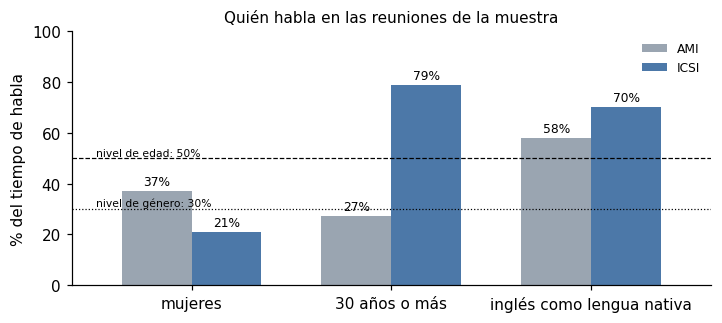

Inglés como lengua nativa, por tiempo de habla -> AMI: 58.0% | ICSI: 70.0%


In [20]:
# [FIG2] Género, edad y lengua nativa por tiempo de habla
nat_ami = ami_habla[ami_habla.lengua_nativa == "English"].dur.sum() / ami_habla[ami_habla.lengua_nativa.notna()].dur.sum()
nat_icsi = icsi_habla[icsi_habla.nativo_ingles == True].dur.sum() / icsi_habla[icsi_habla.nativo_ingles.notna()].dur.sum()
barras = pd.DataFrame({"mujeres": [decl.mujeres["AMI"], decl.mujeres["ICSI"]], "30 años o más": [e_ami[0], e_icsi[0]],
                       "inglés como lengua nativa": [nat_ami, nat_icsi]}, index=["AMI", "ICSI"]) * 100
ax = barras.T.plot.bar(figsize=(7.5, 3), color=["#9aa5b1", "#4c78a8"], rot=0, width=.7)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f%%", fontsize=8, padding=2)
ax.axhline(30, ls=":", c="k", lw=.8); ax.axhline(50, ls="--", c="k", lw=.8)
ax.text(-.48, 31, "nivel de género: 30%", fontsize=7); ax.text(-.48, 51, "nivel de edad: 50%", fontsize=7)
ax.set_ylabel("% del tiempo de habla"); ax.set_ylim(0, 100); ax.legend(frameon=False, fontsize=8)
ax.set_title("Quién habla en las reuniones de la muestra", fontsize=10)
plt.savefig(FIG / "fig2_quien_habla.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Inglés como lengua nativa, por tiempo de habla -> AMI: {pct(nat_ami)} | ICSI: {pct(nat_icsi)}")

In [21]:
# [R3] Representatividad · habla espontánea sobre el total
digitos = icsi_t[icsi_t.lectura_de_digitos & (icsi_t.n_palabras > 0)].dur.sum()
total_habla = ami_habla.dur.sum() + icsi_habla.dur.sum()
r3 = 1 - digitos / total_habla
registrar("R3", f"{pct(r3)} del tiempo de habla es espontáneo; el resto es lectura de dígitos en ICSI "
                f"({H(digitos):.1f} h de {H(total_habla):.0f} h)", "sí" if r3 >= .5 else "no")

[R3] Representatividad · estilo
   nivel:     ≥ 50% de las horas de habla espontánea
   resultado: 97.9% del tiempo de habla es espontáneo; el resto es lectura de dígitos en ICSI (3.5 h de 168 h)  (medido)
   cumple:    sí


,fuente,sesiones,de_3_a_8,mediana,mín,máx,habla_superpuesta
0,AMI,171,100.0%,4.0,3,5,17.4%
1,ICSI,75,89.3%,6.0,3,10,10.6%
2,VoxConverse,448,56.9%,5.0,1,21,3.3%


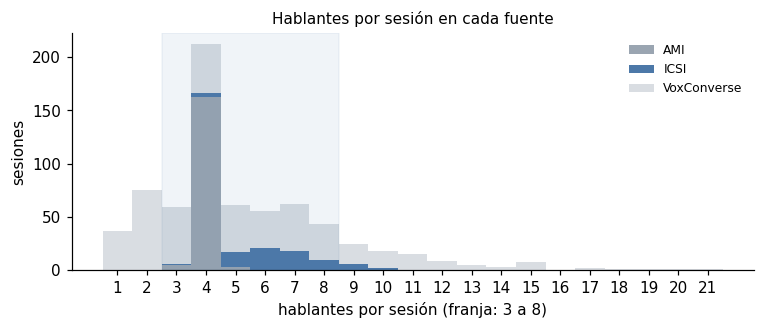

[R4] Representatividad · tamaño de la reunión
   nivel:     ≥ 50% de las sesiones con 3 a 8 hablantes
   resultado: 71.0% de las 694 sesiones tienen de 3 a 8 hablantes (AMI 100.0%, ICSI 89.3%, VoxConverse 56.9%)  (medido)
   cumple:    sí
   nota:      Habla superpuesta: 17.4% del tiempo con habla en AMI, 10.6% en ICSI y 3.3% en VoxConverse


In [22]:
# [R4] Representatividad · tamaño de la reunión (3 a 8 hablantes) y habla superpuesta
tam = {"AMI": ami_r.n_hablantes, "ICSI": icsi_r.n_hablantes, "VoxConverse": vox_s.n_hablantes}
r4 = pd.DataFrame([{"fuente": k, "sesiones": len(v), "de_3_a_8": v.between(3, 8).mean(), "mediana": v.median(),
                    "mín": v.min(), "máx": v.max()} for k, v in tam.items()])

def superpuesta(t, ini="inicio", fin="fin", grupo="reunion"):
    """Fracción del tiempo con habla en la que hablan dos o más personas a la vez."""
    con_uno = con_dos = 0.0
    for _, g in t.dropna(subset=[ini, fin]).groupby(grupo):
        ev = np.concatenate([np.c_[g[ini].to_numpy(), np.ones(len(g))], np.c_[g[fin].to_numpy(), -np.ones(len(g))]])
        ev = ev[np.lexsort((ev[:, 1], ev[:, 0]))]
        activos, tramo = np.cumsum(ev[:, 1])[:-1], np.diff(ev[:, 0])
        con_uno += tramo[activos >= 1].sum(); con_dos += tramo[activos >= 2].sum()
    return con_dos / con_uno

r4["habla_superpuesta"] = [superpuesta(ami_t[ami_t.n_palabras > 0]), superpuesta(icsi_t[icsi_t.n_palabras > 0]),
                           superpuesta(vox.assign(fin=vox.inicio + vox.duracion), grupo="sesion")]
display(r4.assign(de_3_a_8=r4.de_3_a_8.map(pct), habla_superpuesta=r4.habla_superpuesta.map(pct)))
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist([v.clip(upper=21) for v in tam.values()], bins=np.arange(.5, 22.5, 1), stacked=True, label=list(tam),
        color=["#9aa5b1", "#4c78a8", "#d9dde2"])
ax.axvspan(2.5, 8.5, color="#4c78a8", alpha=.08); ax.set_xlabel("hablantes por sesión (franja: 3 a 8)")
ax.set_ylabel("sesiones"); ax.legend(frameon=False, fontsize=8); ax.set_xticks(range(1, 22))
ax.set_title("Hablantes por sesión en cada fuente", fontsize=10)
fig.savefig(FIG / "fig3_hablantes_por_sesion.png", dpi=150, bbox_inches="tight"); plt.show()
todas = pd.concat(tam.values())
registrar("R4", f"{pct(todas.between(3, 8).mean())} de las {len(todas)} sesiones tienen de 3 a 8 hablantes "
                f"(AMI {pct(r4.de_3_a_8[0])}, ICSI {pct(r4.de_3_a_8[1])}, VoxConverse {pct(r4.de_3_a_8[2])})",
          "sí" if todas.between(3, 8).mean() >= .5 else "no",
          nota=f"Habla superpuesta: {pct(r4.habla_superpuesta[0])} del tiempo con habla en AMI, "
               f"{pct(r4.habla_superpuesta[1])} en ICSI y {pct(r4.habla_superpuesta[2])} en VoxConverse")

In [23]:
# [R6] Representatividad · horas de reuniones reales (no actuadas)
h_act = H(ami_r[ami_r.tipo == "scenario"].duracion_s.sum())
h_real_ami = H(ami_r[ami_r.tipo == "nonscenario"].duracion_s.sum())
h_icsi = H(icsi_r.duracion_s.sum())
r6 = (h_real_ami + h_icsi) / (h_act + h_real_ami + h_icsi)
display(pd.DataFrame([
    {"fuente": "AMI · actuadas (un equipo diseña un control remoto, con roles asignados)", "reuniones": int((ami_r.tipo == "scenario").sum()), "horas": h_act},
    {"fuente": "AMI · reales", "reuniones": int((ami_r.tipo == "nonscenario").sum()), "horas": h_real_ami},
    {"fuente": "ICSI · reales (grupos de investigación)", "reuniones": len(icsi_r), "horas": h_icsi},
]).round(1))
registrar("R6", f"{pct(r6)} de las horas de reunión son reales: {h_icsi:.1f} h de ICSI y {h_real_ami:.1f} h de AMI, "
                f"contra {h_act:.1f} h actuadas de AMI", "sí" if r6 >= .30 else "no",
          nota="Las reales son de grupos de investigación, no de empresas")

,fuente,reuniones,horas
0,"AMI · actuadas (un equipo diseña un control remoto, con roles asignados)",138,72.5
1,AMI · reales,33,27.5
2,ICSI · reales (grupos de investigación),75,71.7


[R6] Representatividad · reuniones reales
   nivel:     ≥ 30% de las horas de reuniones no actuadas
   resultado: 57.8% de las horas de reunión son reales: 71.7 h de ICSI y 27.5 h de AMI, contra 72.5 h actuadas de AMI  (medido)
   cumple:    sí
   nota:      Las reales son de grupos de investigación, no de empresas


## 6. Confiabilidad

,fuente,qué declara,procedencia
0,AMI,Transcripción manual con guía. Los tiempos de cada palabra salen de una alineación automática,documentación del corpus
1,ICSI,Transcripción manual. Los participantes pudieron pedir que se quite audio,documentación del corpus
2,VoxConverse,Tiempos generados por un sistema automático y corregidos a mano,ficha


,corpus,reunion,habla_anotada,auc
0,ami,ES2007c,91.5%,0.923
1,ami,ES2005c,93.7%,0.899
2,ami,ES2012c,0.0%,NaN
3,ami,ES2014d,79.9%,0.800
4,ami,IS1006a,97.5%,0.913
5,ami,IS1004b,100.0%,NaN
6,ami,IS1003a,47.9%,0.751
7,ami,IS1002d,98.6%,0.940
8,ami,TS3008a,74.0%,0.922
9,ami,TS3010a,22.9%,0.866


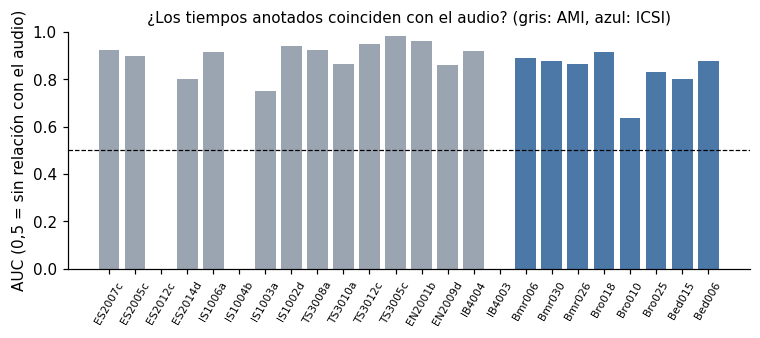

[F1] Confiabilidad · transcripción
   nivel:     100% hecha o validada por personas, con procedimiento documentado
   resultado: Las dos fuentes con transcripción la declaran hecha por personas. Medido: en 21 extractos de audio, la energía separa el habla anotada del silencio con AUC mediana de 0.89 (mínimo 0.64); 0 extractos por debajo de 0,6  (estimado)
   cumple:    sí
   nota:      El AUC verifica los tiempos, no las palabras


In [24]:
# [F1] Confiabilidad · transcripción hecha por personas; cotejo de los tiempos contra el audio
doc = pd.DataFrame([
    ("AMI", "Transcripción manual con guía. Los tiempos de cada palabra salen de una alineación automática", "documentación del corpus"),
    ("ICSI", "Transcripción manual. Los participantes pudieron pedir que se quite audio", "documentación del corpus"),
    ("VoxConverse", "Tiempos generados por un sistema automático y corregidos a mano", "ficha"),
], columns=["fuente", "qué declara", "procedencia"])
display(doc)

def cotejo(corpus, tabla, turnos, paso=0.02):
    """Por extracto: cuánto mejor que el azar separa la energía del audio el habla anotada del silencio (AUC)."""
    filas = []
    for _, x in tabla.iterrows():
        datos, hz = sf.read(M / corpus / x.archivo, dtype="float32", always_2d=True)
        mono = datos.mean(axis=1)
        n = int(hz * paso)
        cuadros = mono[: len(mono) // n * n].reshape(-1, n)
        energia = np.sqrt((cuadros ** 2).mean(axis=1))
        t = turnos[(turnos.reunion == x.reunion) & (turnos.n_palabras > 0)]
        centro = x.inicio_s + (np.arange(len(energia)) + .5) * paso
        habla = np.zeros(len(energia), bool)
        for ini, fin in zip(t.inicio, t.fin):
            habla |= (centro >= ini) & (centro < fin)
        if habla.all() or not habla.any():
            auc = np.nan
        else:   # AUC por rangos (Mann-Whitney)
            rangos = pd.Series(energia).rank().to_numpy()
            auc = (rangos[habla].sum() - habla.sum() * (habla.sum() + 1) / 2) / (habla.sum() * (~habla).sum())
        filas.append({"corpus": corpus, "reunion": x.reunion, "habla_anotada": habla.mean(), "auc": auc})
    return pd.DataFrame(filas)

cj = pd.concat([cotejo("ami", ami_x, ami_t), cotejo("icsi", icsi_x, icsi_t)], ignore_index=True)
display(cj.assign(habla_anotada=cj.habla_anotada.map(pct)).round(3))
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(cj.reunion, cj.auc.fillna(0), color=np.where(cj.corpus == "ami", "#9aa5b1", "#4c78a8"))
ax.axhline(.5, ls="--", c="k", lw=.8)
ax.set_ylim(0, 1); ax.set_ylabel("AUC (0,5 = sin relación con el audio)"); ax.tick_params(axis="x", rotation=60, labelsize=7)
ax.set_title("¿Los tiempos anotados coinciden con el audio? (gris: AMI, azul: ICSI)", fontsize=10)
fig.savefig(FIG / "fig4_tiempos_contra_audio.png", dpi=150, bbox_inches="tight"); plt.show()
validos = cj.auc.dropna()
registrar("F1", f"Las dos fuentes con transcripción la declaran hecha por personas. Medido: en {len(validos)} extractos "
                f"de audio, la energía separa el habla anotada del silencio con AUC mediana de {validos.median():.2f} "
                f"(mínimo {validos.min():.2f}); {int((validos < .6).sum())} extractos por debajo de 0,6",
          "sí" if validos.median() >= .7 else "parcial", tipo="estimado",
          nota="El AUC verifica los tiempos, no las palabras")

In [25]:
# [F3] Confiabilidad · error de la referencia (doble transcripción hecha por el equipo)
minutos = (len(ami_x) + len(icsi_x)) * 30 / 60
registrar("F3", f"Pendiente: doble transcripción de los {len(ami_x) + len(icsi_x)} extractos ({minutos:.0f} min de audio)",
          "sin decidir", tipo="no medido")

[F3] Confiabilidad · error de la referencia
   nivel:     ≤ 2% de palabras en desacuerdo entre dos personas del equipo que transcriben por separado la misma muestra chica
   resultado: Pendiente: doble transcripción de los 24 extractos (12 min de audio)  (no medido)
   cumple:    sin decidir


## 7. Minuta de referencia

Solo AMI: es la única fuente con resumen, decisiones y acciones escritos por personas. La referencia tiene un anotador por reunión.

In [26]:
# [M1] Volumen · minuta de referencia de AMI (resumen, decisiones y acciones)
por_tipo = ami_m.groupby("tipo").agg(items=("item_id", "size"), reuniones=("reunion", "nunique"))
por_tipo["items_por_reunion"] = (por_tipo["items"] / por_tipo["reuniones"]).round(1)
display(por_tipo)

conteo_m = ami_m.groupby(["reunion", "tipo"]).size().unstack(fill_value=0)
completas_m = conteo_m[(conteo_m.resumen > 0) & (conteo_m.decision > 0) & (conteo_m.accion > 0)]
por_grupo = (ami_r.assign(grupo=ami_r.reunion.str[:2])
             .groupby("grupo").agg(reuniones=("reunion", "size"), con_minuta=("tiene_minuta", "sum"),
                                   horas=("duracion_s", lambda s: H(s.sum()))).round(1))
display(por_grupo)

print("Ejemplo de minuta de referencia (ES2008a):")
display(ami_m[ami_m.reunion == "ES2008a"][["tipo", "orden", "texto"]].reset_index(drop=True))

series_m = ami_r[ami_r.reunion.isin(completas_m.index)].serie.nunique()
registrar("M1", f"{len(completas_m)} reuniones con resumen, decisiones y acciones de referencia, en {series_m} series "
                f"({int(ami_r.tiene_minuta.sum())} de {len(ami_r)} reuniones tienen alguna minuta; "
                f"{len(ami_m)} ítems en total)",
          "sí" if len(completas_m) >= 10 else "no",
          nota="Las reuniones EN e IN (no actuadas) no tienen minuta; hay 2 sin decisiones y 9 sin acciones")

,items,reuniones,items_por_reunion
tipo,,,
accion,306,133,2.3
decision,694,140,5.0
problema,450,141,3.2
resumen,1199,142,8.4


,reuniones,con_minuta,horas
grupo,,,
EN,16,0,15.0
ES,60,60,30.4
IB,7,4,4.3
IN,10,0,8.2
IS,38,38,17.8
TS,40,40,24.3


Ejemplo de minuta de referencia (ES2008a):


,tipo,orden,texto
0,resumen,1,The project manager opened the meeting and introduced herself to the team.
1,resumen,2,The project manager introduced the upcoming project in which the team is to create a remote control.
2,resumen,3,The team members participated in a tool training exercise in which they each drew their favorite animal on...
3,resumen,4,"The project manager then talked about the project finances and discussed selling prices, profit aim, marke..."
4,resumen,5,The project manager then led the team in a discussion on their experiences with remotes and what features ...
5,resumen,6,The team members discussed the option of combining remotes and how to produce a remote which is capable of...
6,accion,1,The project manager will investigate whether the team is to create a remote that is to be sued solely with...
7,accion,2,The industrial designer will work on the working design.
8,accion,3,The user interface designer will work on technical functions.
9,accion,4,The project manager will type up the minutes of the current meeting and e-mail those to the team members.


[M1] Volumen · minuta de referencia
   nivel:     ≥ 10 reuniones con resumen, decisiones y acciones de referencia
   resultado: 131 reuniones con resumen, decisiones y acciones de referencia, en 37 series (142 de 171 reuniones tienen alguna minuta; 2649 ítems en total)  (medido)
   cumple:    sí
   nota:      Las reuniones EN e IN (no actuadas) no tienen minuta; hay 2 sin decisiones y 9 sin acciones


In [27]:
# [M2] Representatividad · horas de reuniones con minuta que no son actuadas
con_m = ami_r[ami_r.tiene_minuta]
h_con_m = H(con_m.duracion_s.sum())
h_real_m = H(con_m[con_m.tipo == "nonscenario"].duracion_s.sum())
m2 = h_real_m / h_con_m
display(con_m.assign(tipo=con_m.tipo.map({"scenario": "actuadas", "nonscenario": "reales"}))
        .groupby("tipo").agg(reuniones=("reunion", "size"), horas=("duracion_s", lambda s: H(s.sum()))).round(1))
grupos_reales = ", ".join(sorted(con_m[con_m.tipo == "nonscenario"].reunion.str[:2].unique())) or "ninguno"
registrar("M2", f"{pct(m2)} de las horas con minuta son de reuniones no actuadas ({h_real_m:.1f} h de {h_con_m:.1f} h)",
          "sí" if m2 >= .30 else "no",
          nota=f"Grupos de reuniones reales con minuta: {grupos_reales}. El resto es el escenario del control remoto")

,reuniones,horas
tipo,,
actuadas,138,72.5
reales,4,2.6


[M2] Representatividad · minuta de reuniones reales
   nivel:     ≥ 30% de las horas de reuniones con minuta de referencia son de reuniones no actuadas
   resultado: 3.5% de las horas con minuta son de reuniones no actuadas (2.6 h de 75.1 h)  (medido)
   cumple:    no
   nota:      Grupos de reuniones reales con minuta: IB. El resto es el escenario del control remoto


In [28]:
# [M3] Confiabilidad · el juez (LLM) coincide con la anotación humana
registrar("M3", "Pendiente: el equipo etiqueta a mano una muestra de ítems de minuta y se compara contra el juez",
          "sin decidir", tipo="no medido")

[M3] Confiabilidad · juez de la minuta
   nivel:     El juez (LLM) coincide con la anotación humana en ≥ 80% de los ítems de una muestra etiquetada por el equipo (κ de Cohen ≥ 0,6)
   resultado: Pendiente: el equipo etiqueta a mano una muestra de ítems de minuta y se compara contra el juez  (no medido)
   cumple:    sin decidir


## 8. Exposición al *leakage*

No se entrena ningún modelo. Se busca lo que inflaría la evaluación: datos que el modelo ya vio, personas repetidas entre particiones e información que el producto no tiene al predecir.

In [29]:
# [L1] La definición · columnas que se completan después del momento de predecir
# Al predecir, el producto solo tiene el audio. Todo lo demás es anotación posterior.
ROL = {"texto": "referencia", "n_palabras": "referencia", "hablante": "referencia", "agente": "referencia",
       "inicio": "referencia", "fin": "referencia", "duracion": "referencia", "dur": "referencia",
       "lectura_de_digitos": "referencia", "n_hablantes": "referencia", "hablantes": "referencia",
       "palabras": "referencia", "palabras_sin_tiempo": "referencia", "duracion_s": "referencia",
       "audio_url": "entrada", "archivo": "entrada"}
cols = pd.DataFrame([{"tabla": t, "columna": c, "rol": ROL.get(c, "metadato")} for t, d in TABLAS.items() for c in d.columns])
display(cols.groupby(["tabla", "rol"]).columna.agg(", ".join).unstack(fill_value="—"))
n_ref, n_ent = int((cols.rol == "referencia").sum()), int((cols.rol == "entrada").sum())
registrar_fuga("L1", "La definición",
               f"{n_ref} de {len(cols)} columnas son anotación posterior a la reunión; {n_ent} apuntan al audio, que es "
               f"lo único que recibe el producto. No se le pasa al sistema ni la cantidad de hablantes ni los tiempos de habla")

rol,entrada,metadato,referencia
tabla,,,
ami/extractos,archivo,"reunion, inicio_s",duracion_s
ami/minutas,—,"reunion, tipo, orden, item_id",texto
ami/participantes,—,"sexo, edad, lengua_nativa",hablante
ami/reuniones,audio_url,"reunion, serie, tipo, fecha_cruda, anio, particion_oficial, particion_pyannote, audio_disponible, audio_by...","duracion_s, n_hablantes, hablantes, palabras, palabras_sin_tiempo"
ami/turnos,—,reunion,"agente, hablante, inicio, fin, n_palabras, texto, dur"
icsi/extractos,archivo,"reunion, inicio_s",duracion_s
icsi/hablantes,—,"genero, edad, educacion, nativo_ingles, fecha_formulario",hablante
icsi/reuniones,audio_url,"reunion, grupo, audio_disponible, audio_bytes, audio_hz, audio_canales, audio_bits, audio_duracion_s, ulti...","duracion_s, n_hablantes, hablantes, palabras, palabras_sin_tiempo"
icsi/turnos,—,reunion,"agente, hablante, inicio, fin, lectura_de_digitos, n_palabras, texto, dur"


[L1] La definición
   33 de 85 columnas son anotación posterior a la reunión; 5 apuntan al audio, que es lo único que recibe el producto. No se le pasa al sistema ni la cantidad de hablantes ni los tiempos de habla


In [30]:
# [L2] El tiempo · ¿el modelo ya vio estos datos?
py = ami_r.particion_pyannote.fillna("").replace("", "no figura").value_counts()
print("AMI · partición que usa pyannote:", py.to_dict())
print("AMI · partición oficial del corpus:", ami_r.particion_oficial.fillna("").replace("", "sin partición").value_counts().to_dict())
entrenamiento = int(py.get("train", 0) + py.get("dev", 0))
limpias = int(py.get("test", 0)) + len(icsi_r)
registrar_fuga("L2", "El tiempo",
               f"Grabado en {anios_icsi.min()}–{ami_r.anio.max()} y público hace más de 15 años. pyannote declara AMI y "
               f"VoxConverse como datos de entrenamiento: {entrenamiento} de {len(ami_r)} reuniones de AMI están en su parte "
               f"de entrenamiento o ajuste y {int(py.get('test', 0))} en la de prueba. ICSI no figura. Quedan {limpias} "
               f"reuniones con transcripción que pyannote no declara haber visto ({int(py.get('test', 0))} de AMI y "
               f"{len(icsi_r)} de ICSI). Whisper no publica sus datos de entrenamiento")

AMI · partición que usa pyannote: {'train': 136, 'dev': 18, 'test': 16, 'no figura': 1}
AMI · partición oficial del corpus: {'training': 98, 'sin partición': 33, 'development': 20, 'unseen': 20}
[L2] El tiempo
   Grabado en 2001–2005 y público hace más de 15 años. pyannote declara AMI y VoxConverse como datos de entrenamiento: 154 de 171 reuniones de AMI están en su parte de entrenamiento o ajuste y 16 en la de prueba. ICSI no figura. Quedan 91 reuniones con transcripción que pyannote no declara haber visto (16 de AMI y 75 de ICSI). Whisper no publica sus datos de entrenamiento


In [31]:
# [L3] Los duplicados · frases repetidas entre reuniones distintas
def largos(t, grupo):
    d = t[t.n_palabras >= 8].assign(clave=lambda x: x.texto.str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.strip())
    return d.assign(en_otras=d.clave.map(d.groupby("clave")[grupo].nunique()) > 1)

ami_l = largos(ami_t.merge(ami_r[["reunion", "serie"]], on="reunion"), "serie")
icsi_l = largos(icsi_t.assign(grupo=icsi_t.reunion.str[:3]), "reunion")
display(ami_l[ami_l.en_otras][["reunion", "texto"]].sort_values("texto").head(6))
registrar_fuga("L3", "Los duplicados",
               f"Turnos de 8 palabras o más repetidos palabra por palabra en otra serie: {int(ami_l.en_otras.sum())} de "
               f"{len(ami_l)} en AMI y {int(icsi_l.en_otras.sum())} de {len(icsi_l)} en ICSI. Filas duplicadas exactas: 0 (K1)")

,reunion,texto


[L3] Los duplicados
   Turnos de 8 palabras o más repetidos palabra por palabra en otra serie: 0 de 31174 en AMI y 2 de 40783 en ICSI. Filas duplicadas exactas: 0 (K1)


In [32]:
# [L4] Los grupos · las mismas personas en varias reuniones
ami_hs = ami_r.assign(h=ami_r.hablantes.str.split(";")).explode("h")
series_por_h = ami_hs.groupby("h").serie.nunique()
por_particion = ami_hs[ami_hs.particion_pyannote != ""].groupby("particion_pyannote").h.agg(set)
prueba = por_particion.get("test", set())
repetidos = prueba & (por_particion.get("train", set()) | por_particion.get("dev", set()))
series_partidas = int((ami_r[ami_r.particion_pyannote.fillna("") != ""].groupby("serie").particion_pyannote.nunique() > 1).sum())
icsi_hs = icsi_r.assign(h=icsi_r.hablantes.str.split(";")).explode("h")
reuniones_por_h = icsi_hs.groupby("h").reunion.nunique()
print("AMI · reuniones por serie:", ami_r.groupby("serie").size().value_counts().sort_index().to_dict(),
      "| hablantes en más de una serie:", int((series_por_h > 1).sum()), "de", len(series_por_h))
print("AMI · en la partición de pyannote: series repartidas entre dos partes:", series_partidas,
      "| hablantes de la parte de prueba que también están en entrenamiento:", len(repetidos), "de", len(prueba))
print("ICSI · reuniones por grupo:", icsi_r.grupo.value_counts().to_dict(),
      "| hablantes que están en más de 10 reuniones:", int((reuniones_por_h > 10).sum()), "de", len(reuniones_por_h))
registrar_fuga("L4", "Los grupos",
               f"AMI: {len(ami_r)} reuniones en {ami_r.serie.nunique()} series con las mismas personas; "
               f"{int((series_por_h > 1).sum())} de {len(series_por_h)} hablantes están en más de una serie. La partición de "
               f"pyannote no reparte series ni hablantes entre entrenamiento y prueba ({len(repetidos)} de {len(prueba)} "
               f"repetidos). ICSI: {icsi_r.grupo.nunique()} grupos; un mismo hablante está en {int(reuniones_por_h.max())} de "
               f"{len(icsi_r)} reuniones. Se parte por serie y por hablante")

AMI · reuniones por serie: {1: 3, 2: 2, 3: 3, 4: 36, 5: 1, 6: 1} | hablantes en más de una serie: 17 de 190
AMI · en la partición de pyannote: series repartidas entre dos partes: 0 | hablantes de la parte de prueba que también están en entrenamiento: 0 de 16
ICSI · reuniones por grupo: {'Bmr': 29, 'Bro': 23, 'Bed': 15, 'Bns': 3, 'Btr': 2, 'Bdb': 1, 'Bsr': 1, 'Buw': 1} | hablantes que están en más de 10 reuniones: 16 de 60
[L4] Los grupos
   AMI: 171 reuniones en 46 series con las mismas personas; 17 de 190 hablantes están en más de una serie. La partición de pyannote no reparte series ni hablantes entre entrenamiento y prueba (0 de 16 repetidos). ICSI: 8 grupos; un mismo hablante está en 49 de 75 reuniones. Se parte por serie y por hablante


In [33]:
# [L5] La generación · cómo se produjo cada dato
gen_tabla = pd.DataFrame([
    ("AMI", "Voluntarios actúan un rol (4 por reunión) en un proyecto guionado; se graba en una sala instrumentada",
     pct(h_act / (h_act + h_real_ami)) + " de las horas son de reuniones actuadas", "amicorpus@amiproject.org"),
    ("ICSI", "Reuniones reales de grupos de investigación, que además leen dígitos en voz alta",
     pct(digitos / icsi_habla.dur.sum()) + " del habla es lectura de dígitos", "sitio del corpus"),
    ("VoxConverse", "Videos de YouTube; los tiempos los propone un sistema automático y se corrigen a mano",
     "sin transcripción", "autores (Univ. de Oxford)"),
], columns=["fuente", "cómo se generó (según la documentación)", "medido en la muestra", "a quién preguntarle"])
display(gen_tabla)
registrar_fuga("L5", "La generación",
               f"{pct(h_act / (h_act + h_real_ami))} de las horas de AMI son reuniones actuadas con el mismo guion. "
               f"{pct(digitos / icsi_habla.dur.sum())} del habla de ICSI es lectura de dígitos. En AMI los tiempos de las "
               f"palabras salen de una alineación automática; en VoxConverse, de un sistema automático corregido a mano")

,fuente,cómo se generó (según la documentación),medido en la muestra,a quién preguntarle
0,AMI,Voluntarios actúan un rol (4 por reunión) en un proyecto guionado; se graba en una sala instrumentada,72.5% de las horas son de reuniones actuadas,amicorpus@amiproject.org
1,ICSI,"Reuniones reales de grupos de investigación, que además leen dígitos en voz alta",5.2% del habla es lectura de dígitos,sitio del corpus
2,VoxConverse,Videos de YouTube; los tiempos los propone un sistema automático y se corrigen a mano,sin transcripción,autores (Univ. de Oxford)


[L5] La generación
   72.5% de las horas de AMI son reuniones actuadas con el mismo guion. 5.2% del habla de ICSI es lectura de dígitos. En AMI los tiempos de las palabras salen de una alineación automática; en VoxConverse, de un sistema automático corregido a mano


## 9. Resumen

In [34]:
# [RESUMEN] Todos los niveles y las cinco búsquedas de leakage
res = pd.DataFrame(RESULTADOS)
fug = pd.DataFrame(FUGAS)
res.to_csv(HITO / "resultados_eda.csv", index=False)
fug.to_csv(HITO / "resultados_leakage.csv", index=False)
assert set(res.id) == set(NIVELES.index), "Falta medir o registrar algún nivel"
print(res.cumple.value_counts().to_dict())
with pd.option_context("display.max_colwidth", 200):
    display(res[["id", "propiedad", "tipo", "resultado", "cumple"]])
    display(fug)

{'sí': 15, 'no': 4, 'parcial': 2, 'sin decidir': 2}


,id,propiedad,tipo,resultado,cumple
0,V1,Volumen · transcripción en inglés,medido,171.6 h de reuniones transcriptas y 250 hablantes (AMI: 100.0 h y 190 hablantes; ICSI: 71.7 h y 60),sí
1,V2,Volumen · transcripción de habla espontánea,medido,1764238 palabras de habla espontánea en 164.0 h de habla efectiva (sin silencios ni lectura de dígitos),sí
2,V3,Volumen · separación de hablantes,medido,"694 sesiones y 235 h con turnos con tiempos (AMI 171, ICSI 75, VoxConverse 448)",sí
3,V5,Volumen · las dos etapas juntas (audio → transcripción con hablantes),medido,"222 reuniones de 20 minutos o más con audio disponible, transcripción y hablantes con tiempos (148 de AMI y 74 de ICSI; 165 h)",sí
4,C1,Completitud · transcripción,medido,AMI: 100.0% de los 171 audios disponibles tienen transcripción. ICSI: 100.0% de 75. Palabras sin tiempo: 0.0% en AMI y 11.5% en ICSI,sí
5,C2,Completitud · hablante,medido,100.0% de los turnos tienen hablante en las tres fuentes,sí
6,C5,Completitud · datos demográficos,medido,"AMI: 64.7% de sus 190 hablantes tienen género, edad y lengua nativa. ICSI: 75.0% de 60 (falta sobre todo la edad: 75.0%)",sí
7,K1,Corrección · duplicados exactos,medido,0 duplicados exactos en 6 comprobaciones (máximo 0.0%),sí
8,K2,Corrección · tiempos,medido,"2 turnos con fin ≤ inicio (AMI 2, ICSI 0, VoxConverse 0). 6 turnos terminan después del final del audio",no
9,K3,Corrección · audio,medido,Audio disponible: 171 de 171 en AMI y 75 de 75 en ICSI. El audio cubre todos los turnos anotados en 99.4% de AMI y 98.7% de ICSI. La duración de los metadatos de AMI coincide con el audio solo en ...,parcial


,id,busqueda,resultado
0,L1,La definición,"33 de 85 columnas son anotación posterior a la reunión; 5 apuntan al audio, que es lo único que recibe el producto. No se le pasa al sistema ni la cantidad de hablantes ni los tiempos de habla"
1,L2,El tiempo,Grabado en 2001–2005 y público hace más de 15 años. pyannote declara AMI y VoxConverse como datos de entrenamiento: 154 de 171 reuniones de AMI están en su parte de entrenamiento o ajuste y 16 en ...
2,L3,Los duplicados,Turnos de 8 palabras o más repetidos palabra por palabra en otra serie: 0 de 31174 en AMI y 2 de 40783 en ICSI. Filas duplicadas exactas: 0 (K1)
3,L4,Los grupos,AMI: 171 reuniones en 46 series con las mismas personas; 17 de 190 hablantes están en más de una serie. La partición de pyannote no reparte series ni hablantes entre entrenamiento y prueba (0 de 1...
4,L5,La generación,72.5% de las horas de AMI son reuniones actuadas con el mismo guion. 5.2% del habla de ICSI es lectura de dígitos. En AMI los tiempos de las palabras salen de una alineación automática; en VoxConv...
